**NAMA : Alysha Khanza Dwi Avianti**

**NPM : 24083010123**

**Kelas Analisis Deret Waktu A**

# Pengumpulan Data dan Pembuktian Non-Stasioneritas
**Objek:** Jumlah calon pendonor darah yang ditolak karena kadar hemoglobin (HB) di UDD PMI Kota Surabaya  
**Data:** `data_tolak_hb.csv`, agregasi harian 1 Januari – 31 Agustus 2026 (243 hari)  
**Tujuan:** Membuktikan bahwa data bersifat **non-stasioner** melalui plot rata-rata bulanan, dekomposisi STL, ACF, serta uji formal ADF dan KPSS.


## 1. Memuat Data
Membaca file CSV, mengubah kolom `TglPeriksa` menjadi tanggal (index), lalu memastikan frekuensi harian (`asfreq("D")`) agar tidak ada hari yang terlewat.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

def muat_data(path):
    d = pd.read_csv(path, parse_dates=["TglPeriksa"], index_col="TglPeriksa")
    return d["Jumlah_Pendonor"].asfreq("D").rename("pendonor")

y = muat_data("data_tolak_hb.csv")
print(len(y), "hari | missing:", y.isna().sum())

243 hari | missing: 0


**Hasil:** Data terdiri dari 243 hari observasi tanpa nilai kosong (*missing* = 0), sehingga deret waktu utuh dan siap dianalisis.

## 2. Plot Data Harian dan Rata-rata Bulanan
Menampilkan data harian (garis biru) bersama rata-rata tiap bulan (garis merah). Jika deret stasioner, rata-rata seharusnya relatif konstan sepanjang waktu.

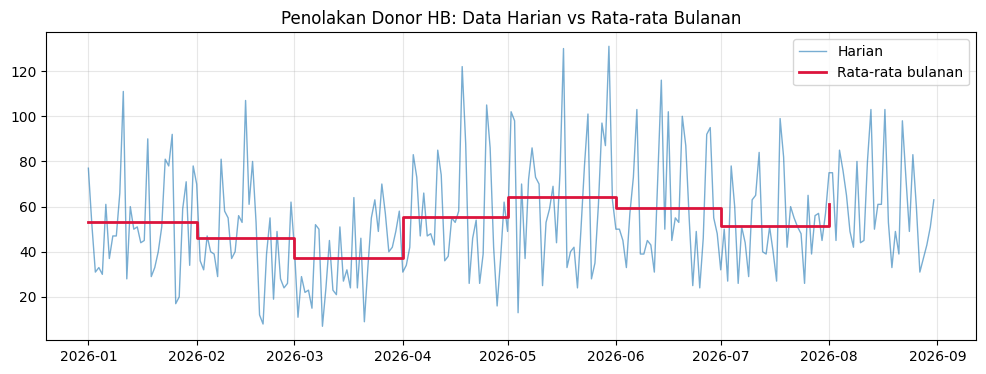

In [2]:
rata_bln = y.resample("MS").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, lw=1, alpha=.6, label="Harian")
ax.step(rata_bln.index, rata_bln.values, where="post", color="crimson", lw=2, label="Rata-rata bulanan")
ax.set_title("Penolakan Donor HB: Data Harian vs Rata-rata Bulanan")
ax.legend(); ax.grid(alpha=.3); plt.show()

**Interpretasi:** Rata-rata bulanan tidak konstan. Nilainya turun dari sekitar 53 (Januari) ke titik terendah sekitar 37 (Maret), lalu naik ke puncak sekitar 64 (Mei), dan bergerak di kisaran 51–61 pada bulan-bulan berikutnya. Data harian juga berfluktuasi lebar (kisaran 7–131). Ini mengindikasikan mean yang berubah seiring waktu, sehingga data tidak stasioner.

## 3. Dekomposisi STL (Seasonal-Trend decomposition using LOESS)
Memisahkan deret menjadi tiga komponen dengan periode musiman 7 hari: **Trend** (arah jangka panjang), **Season** (pola berulang mingguan), dan **Resid** (sisa yang tidak terjelaskan).

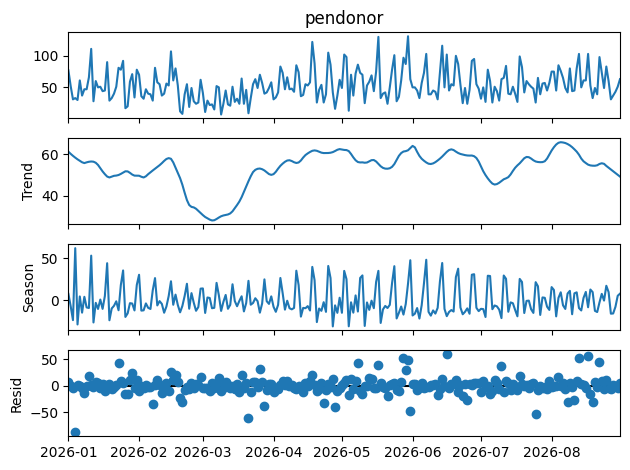

In [3]:
stl = STL(y, period=7, robust=True).fit()
stl.plot(); plt.show()

**Interpretasi:**
- **Trend** tidak mendatar: turun tajam hingga titik terendah pada awal Maret, pulih pada akhir Maret, lalu bertahan di level lebih tinggi pada Mei–Agustus dengan beberapa penurunan. terbukti adanya tren yang berubah.
- **Season** menunjukkan pola naik-turun yang berulang secara teratur, mengonfirmasi adanya musiman mingguan.
- **Resid** tersebar di sekitar nol, artinya sebagian besar pola sudah ditangkap oleh tren dan musiman.

## 4. Autocorrelation Function (ACF)
Mengukur korelasi data dengan dirinya sendiri pada lag 1–35 hari. Batang yang keluar dari area pita biru (batas signifikansi 95%) berarti korelasinya signifikan.

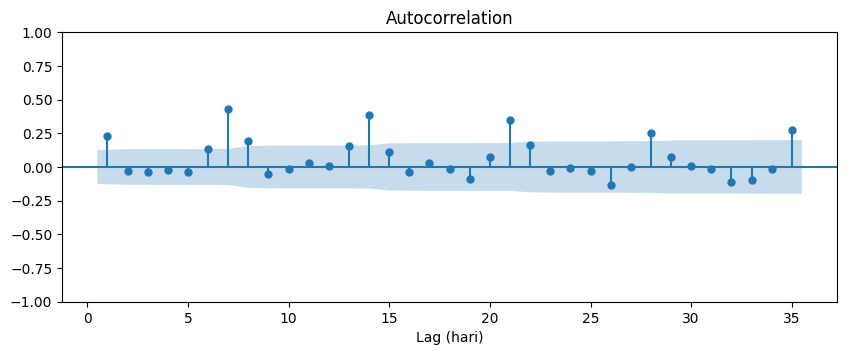

In [4]:
plt.figure(figsize=(10, 3.5))
plot_acf(y, lags=35, zero=False, ax=plt.gca())
plt.xlabel("Lag (hari)"); plt.show()

**Interpretasi:** Korelasi signifikan muncul pada lag **7, 14, 21, 28, dan 35** (kelipatan 7) dengan nilai tertinggi sekitar 0,43 pada lag 7. Lag 1 juga signifikan (sekitar 0,23). Pola kelipatan 7 ini menunjukkan musiman mingguan (s = 7): jumlah penolakan hari ini mirip dengan hari yang sama pada minggu-minggu sebelumnya.

## 5. Uji Stasioneritas Formal: ADF dan KPSS
Dua uji dengan hipotesis yang berlawanan, sehingga hasilnya saling menguatkan:
- **ADF**: H0 = data tidak stasioner. Data stasioner jika p-value < 0,05.
- **KPSS**: H0 = data stasioner. Data tidak stasioner jika p-value < 0,05.

In [5]:
adf = adfuller(y, autolag="AIC")
kp = kpss(y, regression="c", nlags="auto")

hasil = pd.DataFrame({
    "Uji": ["ADF", "KPSS"],
    "Statistik": [round(adf[0], 4), round(kp[0], 4)],
    "p-value": [round(adf[1], 4), round(kp[1], 4)],
    "H0": ["Tidak stasioner", "Stasioner"],
    "Keputusan": ["Gagal tolak H0 → non-stasioner" if adf[1] > 0.05 else "Tolak H0 → stasioner",
                  "Tolak H0 → non-stasioner" if kp[1] < 0.05 else "Gagal tolak H0 → stasioner"],
})
hasil

/tmp/ipykernel_2648/1355038563.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(y, regression="c", nlags="auto")


,Uji,Statistik,p-value,H0,Keputusan
0,ADF,-1.8998,0.3322,Tidak stasioner,Gagal tolak H0 → non-stasioner
1,KPSS,0.9274,0.0100,Stasioner,Tolak H0 → non-stasioner


**Interpretasi:**

| Uji | Statistik | p-value | Keputusan |
|---|---|---|---|
| ADF | -1,8998 | 0,3322 | Gagal tolak H0 → non-stasioner |
| KPSS | 0,9274 | ≤ 0,01 | Tolak H0 → non-stasioner |

ADF memberi p-value 0,3322 (> 0,05), dan KPSS memberi p-value ≤ 0,01 (< 0,05). Kedua uji sama-sama menyimpulkan data non-stasioner.

## Kesimpulan
Data jumlah penolakan donor HB harian **bersifat non-stasioner**, dibuktikan oleh:
1. Rata-rata bulanan dan komponen tren yang berubah sepanjang waktu.
2. Pola musiman mingguan (ACF signifikan pada kelipatan lag 7).
3. Uji ADF (p = 0,3322) dan KPSS (p ≤ 0,01) yang sama-sama menunjukkan non-stasioner.

